# Toric code: ground state degeneracy from the kernel of the rolled stencil

The recipe of `docs/gsd_constraints_and_symmetries.md` §7, applied to the model it was designed to
reproduce as a sanity check. Nothing is derived by hand: the star and plaquette operators are written
as small stencils, `torch.roll` translates them across an $L_y \times L_x$ torus to build the full
linear map $F$ over $GF(p)$, and everything physical is read off $\ker F$ and $\mathrm{rank}\,F$.

**The logic, same four steps as `fractal_constraints_Nc.ipynb`:**

1. "Multiply a generator over the lattice with exponents $t_p$" *is* a linear operator $F$ acting on
   exponent configurations $t$, with the roll supplying the periodic boundary condition.
2. Feeding $F$ a single-site delta returns one **column** of its matrix.
3. Doing that for every site (and every generator species) builds the full map.
4. A relation $\prod_p \mathcal{O}_p^{t_p} = \mathbb{1}$ is exactly $Ft = 0$, so the redundancies are
   $\ker F$ and the independent stabilizers are $\mathrm{rank}\,F$.

**What is different from the fractal notebooks.** Two things:

- **Two species.** The toric code has star ($X$-type) and plaquette ($Z$-type) generators, so $F$ is a
  *block* map (§7.3's "multi-species subtlety"), and the qubits live on **edges**, two per site, not
  on the sites themselves. $F$ is therefore $2N \times N$ per species, not $N \times N$ — a rectangular
  map, and the distinction between $\dim\ker F$ and the GSD exponent stops being cosmetic.
- **The answer is topological, not number-theoretic.** $N_c$ and the GSD come out completely
  independent of $L_x, L_y$ — the exact opposite of the fractal/type-II behaviour where $N_c$ spiked
  only at $L = 2^n - 2^m$. Same machinery, and the machinery is what tells the two cases apart.

**Target:** $\mathrm{GSD} = 4$ on the torus, for every $L_x, L_y$; $p^2$ for $\mathbb{Z}_p$ qudits;
and $2^3$ for the 3D toric code in §10.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

## 1. Geometry, conventions, and the two stencils

**Sites.** A configuration of exponents is a tensor of shape `(Ly, Lx)`; `dim=0` (rows) is the $e_y$
direction, `dim=1` (columns) is $e_x$. Vertices and plaquettes are both labelled by their site $r$
(a plaquette by its lower-left corner).

**Qubits.** Two per site, sitting on the two edges emanating from it:

- `a = 0`: the $x$-edge $e_x(r)$, joining $r$ and $r+e_x$,
- `a = 1`: the $y$-edge $e_y(r)$, joining $r$ and $r+e_y$.

So an edge configuration is a tensor of shape `(2, Ly, Lx)` and there are $n = 2L_xL_y$ qubits — the
same as the number of generators ($L_xL_y$ stars + $L_xL_y$ plaquettes). That coincidence matters in
§6.

**The generators.**

$$A_v = \prod_{e \ni v} X_e^{\pm 1}, \qquad B_f = \prod_{e \in \partial f} Z_e^{\pm 1}$$

with the star carrying $+1$ on the two edges pointing out of $v$ and $-1$ on the two pointing in, and
the plaquette carrying the circulation $+e_x(r), +e_y(r+e_x), -e_x(r+e_y), -e_y(r)$ around its
boundary. Over $GF(2)$ the signs are invisible ($-1 = +1$); they are written in anyway because §9
runs the identical code over $\mathbb{Z}_p$, where they are exactly what makes stars and plaquettes
commute.

**Rolling.** `torch.roll(t, s, d)` sets `new[k] = old[k - s]`, so `torch.roll(t, -1, 1)` evaluates
$t(r + e_x)$, and the wraparound *is* the periodic boundary condition. Collecting which generators
touch a given edge:

$$s_x(r) = t(r) - t(r+e_x), \qquad s_y(r) = t(r) - t(r+e_y) \qquad \text{(stars)}$$
$$s_x(r) = u(r) - u(r-e_y), \qquad s_y(r) = u(r-e_x) - u(r) \qquad \text{(plaquettes)}$$

which is the whole model in four rolls.

In [2]:
def star_support(t, p=2):
    """X-support of prod_v A_v^{t_v}.  t: (Ly, Lx) exponents -> (2, Ly, Lx) edge support."""
    sx = t - torch.roll(t, -1, 1)      # e_x(r): star at r (+1), star at r+e_x (-1)
    sy = t - torch.roll(t, -1, 0)      # e_y(r): star at r (+1), star at r+e_y (-1)
    return torch.stack([sx, sy]) % p

def plaq_support(u, p=2):
    """Z-support of prod_f B_f^{u_f}.  u: (Ly, Lx) exponents -> (2, Ly, Lx) edge support."""
    sx = u - torch.roll(u, 1, 0)       # e_x(r): plaquette at r (+1), at r-e_y (-1)
    sy = torch.roll(u, 1, 1) - u       # e_y(r): plaquette at r-e_x (+1), at r (-1)
    return torch.stack([sx, sy]) % p

Lx, Ly = 5, 4
rand_t = torch.randint(0, 2, (Ly, Lx))
print("Random star exponents t:\n", rand_t.numpy())
print("\nX-support of prod A_v^{t_v}  (x-edges then y-edges):")
print(star_support(rand_t).numpy())
print("\nNonzero entries mean the product is NOT the identity -- it is a leftover Pauli.")
print("A random t is essentially never a relation. We must SOLVE, not sample.")

Random star exponents t:
 [[1 1 0 1 0]
 [1 1 1 1 0]
 [1 0 0 0 0]
 [0 0 1 0 0]]

X-support of prod A_v^{t_v}  (x-edges then y-edges):
[[[0 1 1 1 1]
  [0 0 0 1 1]
  [1 0 0 0 1]
  [0 1 1 0 0]]

 [[0 0 1 0 0]
  [0 1 1 1 0]
  [1 0 1 0 0]
  [1 1 1 1 0]]]

Nonzero entries mean the product is NOT the identity -- it is a leftover Pauli.
A random t is essentially never a relation. We must SOLVE, not sample.


### The two stencils, drawn

The picture below is produced by the same two functions, fed a single-site delta — no separate
plotting model to get out of sync with the algebra.

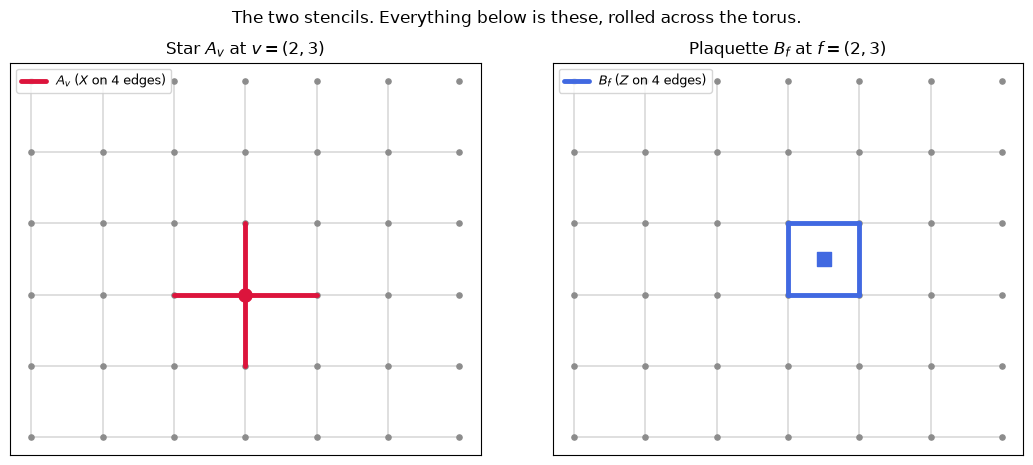

In [3]:
def delta(Lx, Ly, i, j):
    """Single generator at row i (e_y), column j (e_x)."""
    e = torch.zeros((Ly, Lx), dtype=torch.int64)
    e[i, j] = 1
    return e

def edge_ends(a, i, j):
    return ((j, i), (j + 1, i)) if a == 0 else ((j, i), (j, i + 1))

def draw_support(s, ax, color, lw=3.5, label=None):
    s = s.numpy()
    first = True
    for a in range(2):
        for i in range(s.shape[1]):
            for j in range(s.shape[2]):
                if s[a, i, j] != 0:
                    (x0, y0), (x1, y1) = edge_ends(a, i, j)
                    ax.plot([x0, x1], [y0, y1], color=color, lw=lw,
                            solid_capstyle="round", label=label if first else None, zorder=3)
                    first = False

def draw_lattice(Lx, Ly, ax):
    for i in range(Ly):
        for j in range(Lx):
            for a in range(2):
                (x0, y0), (x1, y1) = edge_ends(a, i, j)
                ax.plot([x0, x1], [y0, y1], color="0.85", lw=1.2, zorder=1)
    ax.scatter(*np.array([(j, i) for i in range(Ly + 1) for j in range(Lx + 1)]).T,
               s=14, color="0.55", zorder=2)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

Lx, Ly = 6, 5
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

draw_lattice(Lx, Ly, axes[0])
draw_support(star_support(delta(Lx, Ly, 2, 3)), axes[0], "crimson", label="$A_v$ ($X$ on 4 edges)")
axes[0].scatter([3], [2], marker="o", s=90, c="crimson", zorder=4)
axes[0].set_title("Star $A_v$ at $v=(2,3)$")
axes[0].legend(loc="upper left", fontsize=9)

draw_lattice(Lx, Ly, axes[1])
draw_support(plaq_support(delta(Lx, Ly, 2, 3)), axes[1], "royalblue", label="$B_f$ ($Z$ on 4 edges)")
axes[1].scatter([3.5], [2.5], marker="s", s=90, c="royalblue", zorder=4)
axes[1].set_title("Plaquette $B_f$ at $f=(2,3)$")
axes[1].legend(loc="upper left", fontsize=9)

fig.suptitle("The two stencils. Everything below is these, rolled across the torus.", y=1.0)
plt.tight_layout(); plt.show()

## 2. A delta exposes one column of the map

Apply the roll expression to an exponent configuration that is $1$ at a single site. By the
definition of a matrix, the output *is* that generator's column of $F$: four lit edges, and near the
boundary the support wraps — the PBC for free.

--- star at (row 1, col 2) ---
x-edge support:
 [[0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
y-edge support:
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
edges touched: 4 

--- plaquette at (row 1, col 2) ---
x-edge support:
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
y-edge support:
 [[0 0 0 0 0]
 [0 0 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
edges touched: 4 



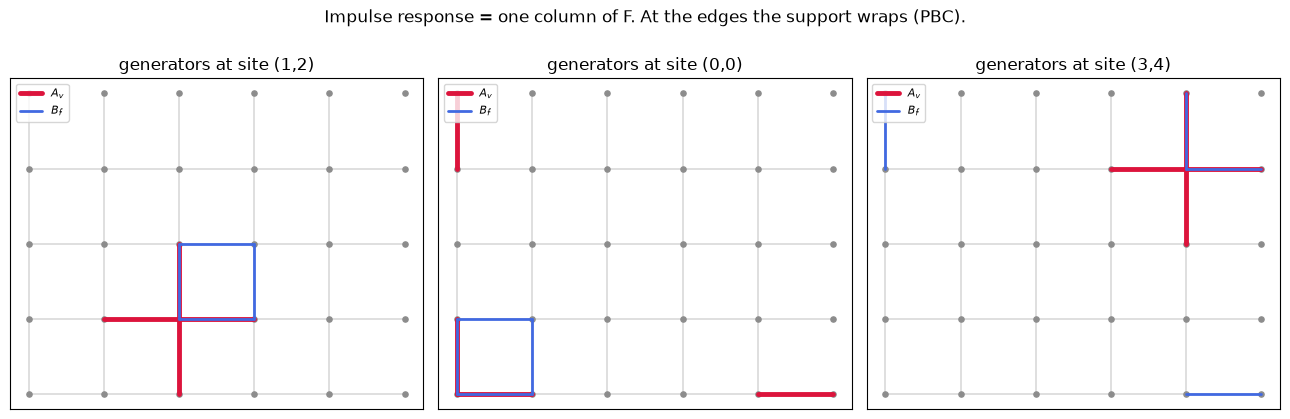

In [4]:
Lx, Ly = 5, 4
for name, fn in [("star", star_support), ("plaquette", plaq_support)]:
    r = fn(delta(Lx, Ly, 1, 2))
    print(f"--- {name} at (row 1, col 2) ---")
    print("x-edge support:\n", r[0].numpy())
    print("y-edge support:\n", r[1].numpy())
    print("edges touched:", int((r != 0).sum()), "\n")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (i, j) in zip(axes, [(1, 2), (0, 0), (3, 4)]):
    draw_lattice(Lx, Ly, ax)
    draw_support(star_support(delta(Lx, Ly, i, j)), ax, "crimson", label="$A_v$")
    draw_support(plaq_support(delta(Lx, Ly, i, j)), ax, "royalblue", lw=2.0, label="$B_f$")
    ax.set_title(f"generators at site ({i},{j})")
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Impulse response = one column of F. At the edges the support wraps (PBC).", y=1.02)
plt.tight_layout(); plt.show()

## 3. Build the full maps $F_A$ and $F_B$

Loop over all $L_xL_y$ sites and stack the impulse responses as columns. Each map takes
$L_xL_y$ exponents to $2L_xL_y$ edge coefficients, so $F$ is **$2N \times N$** — rectangular, unlike
the square $N\times N$ operator of the fractal notebooks, because the qubits and the generators no
longer live on the same set.

Lx=4, Ly=3:  F_A has shape (24, 12),  F_B has shape (24, 12)
column weights, F_A: [4]   F_B: [4]
row weights (edges touched per generator type), F_A: [2]   F_B: [2]


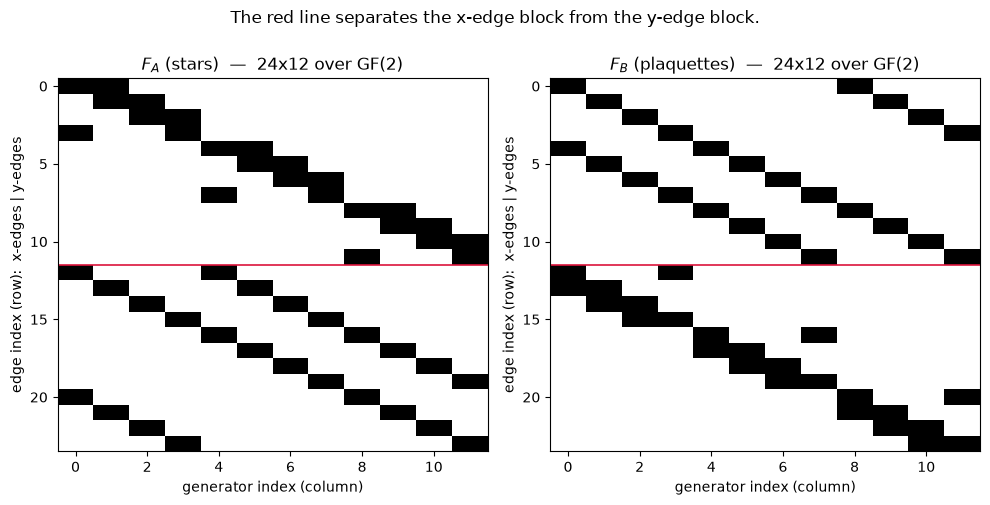

In [5]:
def build_map(support_fn, Lx, Ly, p=2):
    """Columns are impulse responses: F[:, v] = edge support of the single generator at site v."""
    N = Lx * Ly
    F = torch.zeros((2 * N, N), dtype=torch.int64)
    for k in range(N):
        F[:, k] = support_fn(delta(Lx, Ly, k // Lx, k % Lx), p).flatten()
    return F

Lx, Ly, p = 4, 3, 2
Fa, Fb = build_map(star_support, Lx, Ly, p), build_map(plaq_support, Lx, Ly, p)

print(f"Lx={Lx}, Ly={Ly}:  F_A has shape {tuple(Fa.shape)},  F_B has shape {tuple(Fb.shape)}")
print("column weights, F_A:", torch.unique((Fa != 0).sum(0)).tolist(),
      "  F_B:", torch.unique((Fb != 0).sum(0)).tolist())
print("row weights (edges touched per generator type), F_A:",
      torch.unique((Fa != 0).sum(1)).tolist(), "  F_B:", torch.unique((Fb != 0).sum(1)).tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (M, name) in zip(axes, [(Fa, "$F_A$ (stars)"), (Fb, "$F_B$ (plaquettes)")]):
    ax.imshow(M.numpy(), cmap="Greys", interpolation="nearest", aspect="auto")
    ax.axhline(Lx * Ly - 0.5, color="crimson", lw=1.2)
    ax.set_title(f"{name}  —  {2*Lx*Ly}x{Lx*Ly} over GF({p})")
    ax.set_xlabel("generator index (column)")
    ax.set_ylabel("edge index (row):  x-edges | y-edges")
fig.suptitle("The red line separates the x-edge block from the y-edge block.", y=1.0)
plt.tight_layout(); plt.show()

## 4. Linear algebra over $GF(p)$

Rank and nullspace must be taken **over $GF(p)$**, not over the reals — `torch.linalg` would give the
wrong answer. These are the routines from `fractal_constraints_Nc_general.ipynb`, unchanged: pivots
normalised with $a^{-1} = a^{p-2}$ (Fermat, so $p$ must be prime), elimination keeping signs, and the
free-variable coefficient $-R_{if}$ that only degenerates to $+R_{if}$ at $p=2$.

In [6]:
def gfp_inv(a, p):
    """Multiplicative inverse in GF(p) via Fermat's little theorem. p must be prime."""
    a = int(a) % p
    if a == 0:
        raise ZeroDivisionError("0 has no inverse in GF(p)")
    return pow(a, p - 2, p)

def gfp_rref(M, p=2):
    """Row-reduced echelon form over GF(p). Returns (R, pivot_columns)."""
    M = M.clone() % p
    rows, cols = M.shape
    pivots, r = [], 0
    for col in range(cols):
        piv = None
        for rr in range(r, rows):
            if M[rr, col] != 0:
                piv = rr
                break
        if piv is None:
            continue
        M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p
        for rr in range(rows):
            if rr != r and M[rr, col] != 0:
                M[rr] = (M[rr] - M[rr, col] * M[r]) % p
        pivots.append(col)
        r += 1
        if r == rows:
            break
    return M, pivots

def gfp_rank(M, p=2):
    return len(gfp_rref(M, p)[1])

def gfp_nullspace(F, p=2):
    """Basis for {t : F t = 0} over GF(p), one vector per row."""
    R, pivots = gfp_rref(F, p)
    cols = F.shape[1]
    free = [c for c in range(cols) if c not in pivots]
    basis = []
    for f in free:
        v = torch.zeros(cols, dtype=torch.int64)
        v[f] = 1
        for i, pc in enumerate(pivots):
            v[pc] = (-R[i, f]) % p
        basis.append(v)
    return torch.stack(basis) if basis else torch.zeros((0, cols), dtype=torch.int64)

def gfp_rank_fast(M, p=2):
    """Same rank, elimination vectorised as a rank-1 update. Used for the sweeps."""
    M = M.clone() % p
    rows, cols = M.shape
    r = 0
    for col in range(cols):
        nz = (M[r:, col] != 0).nonzero()
        if nz.numel() == 0:
            continue
        piv = r + int(nz[0])
        if piv != r:
            M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p
        factors = M[:, col].clone()
        factors[r] = 0
        M = (M - torch.outer(factors, M[r])) % p
        r += 1
        if r == rows:
            break
    return r

Fa = build_map(star_support, 4, 3, 2)
assert gfp_rank(Fa, 2) == gfp_rank_fast(Fa, 2), "rank routines disagree"
print("rank(F_A) =", gfp_rank(Fa, 2), " (both routines agree)")

rank(F_A) = 11  (both routines agree)


## 5. The kernel: the two global relations

$\ker F_A$ is the set of exponent configurations with $\prod_v A_v^{t_v} = \mathbb{1}$. The roll
expression makes the answer readable by eye before computing it: $t(r) - t(r+e_x) = 0$ for all $r$
*and* $t(r) - t(r+e_y) = 0$ for all $r$ forces $t$ to be constant. On a torus the constant
configuration exists and is unique up to scale, so

$$\dim\ker F_A = 1, \qquad \dim\ker F_B = 1,$$

for every $L_x, L_y$ — the familiar statements $\prod_v A_v = \mathbb{1}$ and
$\prod_f B_f = \mathbb{1}$. Note this is the *whole* kernel: there is no second, larger family, which
is precisely why the toric code has no sub-extensive, size-sensitive degeneracy.

In [7]:
for (Lx, Ly) in [(4, 3), (5, 5), (6, 2)]:
    Fa, Fb = build_map(star_support, Lx, Ly), build_map(plaq_support, Lx, Ly)
    Ka, Kb = gfp_nullspace(Fa), gfp_nullspace(Fb)
    print(f"Lx={Lx}, Ly={Ly}:  dim ker F_A = {Ka.shape[0]},  dim ker F_B = {Kb.shape[0]}")
    print("  star relation t:\n", Ka[0].reshape(Ly, Lx).numpy())

Lx, Ly = 4, 3
Ka = gfp_nullspace(build_map(star_support, Lx, Ly))
Kb = gfp_nullspace(build_map(plaq_support, Lx, Ly))
print("\nplaquette relation u:\n", Kb[0].reshape(Ly, Lx).numpy())

Lx=4, Ly=3:  dim ker F_A = 1,  dim ker F_B = 1
  star relation t:
 [[1 1 1 1]
 [1 1 1 1]
 [1 1 1 1]]
Lx=5, Ly=5:  dim ker F_A = 1,  dim ker F_B = 1
  star relation t:
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Lx=6, Ly=2:  dim ker F_A = 1,  dim ker F_B = 1
  star relation t:
 [[1 1 1 1 1 1]
 [1 1 1 1 1 1]]

plaquette relation u:
 [[1 1 1 1]
 [1 1 1 1]
 [1 1 1 1]]


### Validation

Four checks, the same set the fractal notebooks used, all of which must pass:

1. **Every kernel vector really is a relation** — verified by pushing it back through the *original*
   roll functions, not through the matrix. This closes the loop on the code we started from.
2. **The kernel vectors are linearly independent** — their $GF(p)$ rank equals their count.
3. **Rank–nullity holds**: $\mathrm{rank}\,F + \dim\ker F = L_xL_y$ for each species.
4. **Random $GF(p)$ combinations stay in the kernel** — the kernel is a subspace, not a list of lucky
   configurations. (This check has teeth only for $p>2$; §9 reruns it there.)

In [8]:
def validate(Lx, Ly, p=2, n_random=8, verbose=True):
    ok = True
    for name, fn in [("stars", star_support), ("plaquettes", plaq_support)]:
        F = build_map(fn, Lx, Ly, p)
        K = gfp_nullspace(F, p)
        n = K.shape[0]

        viol = sum(int(fn(v.reshape(Ly, Lx), p).sum() != 0) for v in K)          # check 1
        independent = (gfp_rank(K, p) == n) if n > 0 else True                    # check 2
        rank_nullity = (gfp_rank(F, p) + n == Lx * Ly)                            # check 3
        closed = True                                                             # check 4
        for _ in range(n_random):
            combo = (torch.randint(0, p, (n,)) @ K) % p
            closed &= bool((fn(combo.reshape(Ly, Lx), p) == 0).all())

        ok &= (viol == 0) and independent and rank_nullity and closed
        if verbose:
            print(f"  {name:11s} dim ker = {n}   in kernel: {viol == 0} ({viol} violations)"
                  f"   independent: {independent}   rank-nullity: {rank_nullity}"
                  f"   subspace: {closed}")
    return ok

for (Lx, Ly, p) in [(4, 3, 2), (5, 5, 2), (6, 2, 2)]:
    print(f"Lx={Lx}, Ly={Ly}, p={p}")
    assert validate(Lx, Ly, p), "a validation check failed"
print("\nAll validation checks passed.")

Lx=4, Ly=3, p=2
  stars       dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True
  plaquettes  dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True
Lx=5, Ly=5, p=2


  stars       dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True
  plaquettes  dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True
Lx=6, Ly=2, p=2
  stars       dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True
  plaquettes  dim ker = 1   in kernel: True (0 violations)   independent: True   rank-nullity: True   subspace: True

All validation checks passed.


## 6. From the kernel to the GSD — and one place the shortcut fails

The doc's §1 headline is $\mathrm{GSD} = 2^{\dim\ker F}$. That form is a *special case*. The general
statement is rank–nullity on the stabilizer group:

$$\mathrm{GSD} = p^{\,n - \mathrm{rank}(S)}, \qquad
\mathrm{rank}(S) = m - \dim\ker F = \mathrm{rank}\,F,$$

with $n$ qubits and $m$ generators, so

$$\boxed{\;\mathrm{GSD} = p^{\,(n - m) \;+\; \dim\ker F}\;}$$

and the two agree only when $n = m$. The toric code happens to satisfy this — $n = 2L_xL_y$ edges,
$m = 2L_xL_y$ generators — so here

$$k \;=\; n - \mathrm{rank}\,F_A - \mathrm{rank}\,F_B \;=\; \dim\ker F_A + \dim\ker F_B \;=\; 2,
\qquad \mathrm{GSD} = 2^2 = 4 .$$

The code below computes $k$ the safe way (from ranks) and asserts the kernel shortcut against it,
rather than assuming it.

In [9]:
def gsd(Lx, Ly, p=2):
    """Returns (k, GSD) computed from ranks; asserts the kernel shortcut agrees."""
    Fa, Fb = build_map(star_support, Lx, Ly, p), build_map(plaq_support, Lx, Ly, p)
    n, m = 2 * Lx * Ly, 2 * Lx * Ly
    rank = gfp_rank_fast(Fa, p) + gfp_rank_fast(Fb, p)
    k = n - rank
    dim_ker = m - rank
    assert k == (n - m) + dim_ker, "rank-nullity bookkeeping is inconsistent"
    return k, p ** k

for (Lx, Ly) in [(2, 2), (4, 3), (5, 5), (7, 4)]:
    k, g = gsd(Lx, Ly)
    print(f"Lx={Lx}, Ly={Ly}:  n = {2*Lx*Ly:3d} qubits,  rank(S) = {2*Lx*Ly-k:3d},"
          f"  k = {k},  GSD = {g}")

Lx=2, Ly=2:  n =   8 qubits,  rank(S) =   6,  k = 2,  GSD = 4
Lx=4, Ly=3:  n =  24 qubits,  rank(S) =  22,  k = 2,  GSD = 4
Lx=5, Ly=5:  n =  50 qubits,  rank(S) =  48,  k = 2,  GSD = 4
Lx=7, Ly=4:  n =  56 qubits,  rank(S) =  54,  k = 2,  GSD = 4


### Sweep: the answer does not depend on the system size

This is the whole physical point, and it is the same computation the fractal notebooks ran. There,
$N_c$ was either linear in $L$ (generic subsystem symmetry) or nonzero only at $L = 2^n-2^m$
(fractal, type-II, UV/IR mixing). Here it is flat: $k=2$, $\mathrm{GSD}=4$, for every torus. The
degeneracy is counting the genus of the surface, not the arithmetic of $L$.

k = log_2 GSD   (rows = Ly, cols = Lx, both 2..8)

        2   3   4   5   6   7   8
  2     2   2   2   2   2   2   2
  3     2   2   2   2   2   2   2
  4     2   2   2   2   2   2   2
  5     2   2   2   2   2   2   2
  6     2   2   2   2   2   2   2
  7     2   2   2   2   2   2   2
  8     2   2   2   2   2   2   2

All 49 tori give k = 2, GSD = 4.


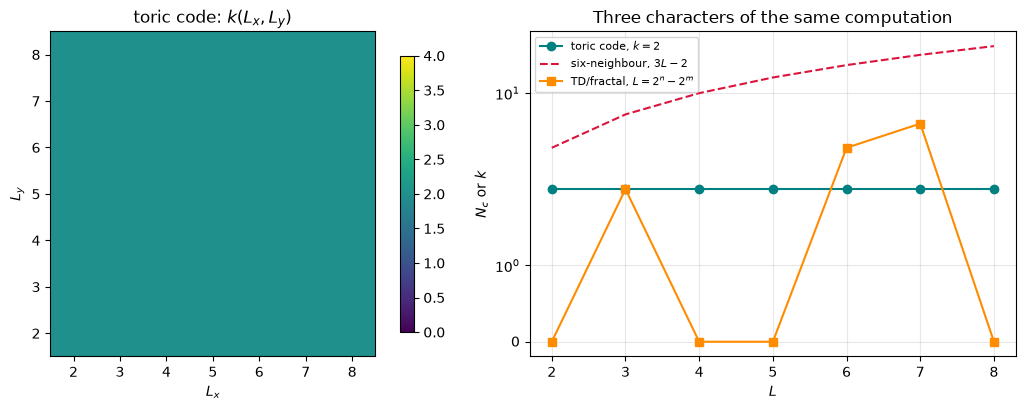

In [10]:
Ls = range(2, 9)
grid = np.zeros((len(Ls), len(Ls)), dtype=int)
for a, Ly in enumerate(Ls):
    for b, Lx in enumerate(Ls):
        grid[a, b] = gsd(Lx, Ly)[0]

print("k = log_2 GSD   (rows = Ly, cols = Lx, both 2..8)\n")
print("     " + "".join(f"{Lx:4d}" for Lx in Ls))
for a, Ly in enumerate(Ls):
    print(f"{Ly:3d}  " + "".join(f"{v:4d}" for v in grid[a]))

assert (grid == 2).all(), "GSD is not 4 somewhere"
print("\nAll 49 tori give k = 2, GSD = 4.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
im = ax[0].imshow(grid, cmap="viridis", origin="lower", vmin=0, vmax=4,
                  extent=[1.5, 8.5, 1.5, 8.5])
ax[0].set_xlabel("$L_x$"); ax[0].set_ylabel("$L_y$"); ax[0].set_title("toric code: $k(L_x,L_y)$")
fig.colorbar(im, ax=ax[0], shrink=0.85)

def td_Nc(L):
    for n in range(2, 14):
        for m in range(0, n - 1):
            if 2 ** n - 2 ** m == L:
                return 2 ** n - 2 ** (m + 1)
    return 0

Lsq = list(Ls)
ax[1].plot(Lsq, [grid[i, i] for i in range(len(Lsq))], "o-", color="teal", label="toric code, $k=2$")
ax[1].plot(Lsq, [3 * L - 2 for L in Lsq], "--", color="crimson", label="six-neighbour, $3L-2$")
ax[1].plot(Lsq, [td_Nc(L) for L in Lsq], "s-", color="darkorange", label="TD/fractal, $L=2^n-2^m$")
ax[1].set_yscale("symlog"); ax[1].set_xlabel("$L$"); ax[1].set_ylabel("$N_c$ or $k$")
ax[1].set_title("Three characters of the same computation")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. The model is actually a commuting-projector model

Everything above is rank–nullity, which (doc §2) is only *about* the ground space if the generators
commute. For a CSS model the check is one matrix product: stars and plaquettes commute iff their
supports overlap in an even number of edges, i.e. iff the pairing

$$\langle A_v, B_f\rangle \;=\; \sum_e (F_A)_{ev}\,(F_B)_{ef} \;=\; 0 \pmod p
\qquad\Longleftrightarrow\qquad F_A^{\mathsf T} F_B \equiv 0 .$$

Stars commute with stars and plaquettes with plaquettes automatically ($X$ with $X$, $Z$ with $Z$).
This is where the orientation signs earn their keep: over $GF(2)$ the check passes either way, but
over $\mathbb{Z}_p$ it fails without them — the $\mathbb{Z}_p$ run in §9 is the real test.

In [11]:
for (Lx, Ly, p) in [(4, 3, 2), (5, 5, 2), (5, 4, 3), (4, 4, 7)]:
    Fa, Fb = build_map(star_support, Lx, Ly, p), build_map(plaq_support, Lx, Ly, p)
    pairing = (Fa.T @ Fb) % p
    print(f"Lx={Lx}, Ly={Ly}, p={p}:  max |<A_v, B_f>| = {int(pairing.abs().max())}"
          f"   -> all generators commute: {bool((pairing == 0).all())}")
    assert bool((pairing == 0).all()), "stars and plaquettes do not commute"
print("\nCommuting-projector condition verified: rank-nullity is a statement about the ground space.")

Lx=4, Ly=3, p=2:  max |<A_v, B_f>| = 0   -> all generators commute: True
Lx=5, Ly=5, p=2:  max |<A_v, B_f>| = 0   -> all generators commute: True
Lx=5, Ly=4, p=3:  max |<A_v, B_f>| = 0   -> all generators commute: True
Lx=4, Ly=4, p=7:  max |<A_v, B_f>| = 0   -> all generators commute: True

Commuting-projector condition verified: rank-nullity is a statement about the ground space.


## 8. Truncating the relation: from $\ker F$ to the logical operators

Doc §3 and §7.3, the part that is easy to get wrong: a kernel vector applied in full is the
*identity*, not a symmetry. The physical operator comes from **truncating** it — running the product
over part of the lattice only and keeping what is left over at the cut.

Take the star relation $t \equiv 1$ and truncate it to the columns $j < w$. Inside the strip
everything cancels; the leftovers are the two boundaries of the strip:

$$\prod_{j<w}\prod_i A_{(i,j)} \;=\; \Big(\prod_i X_{e_x(i,\,w-1)}\Big)\Big(\prod_i X_{e_x(i,\,L_x-1)}\Big)^{-1},$$

two non-contractible **dual**-lattice loops of $X$ winding in $y$. Widening the strip slides one loop
across the torus; closing it up recovers $\prod_v A_v = \mathbb{1}$, which is why the two loops are
equivalent up to stabilizers. Truncating the *plaquette* relation instead gives closed $Z$ loops on
the direct lattice.

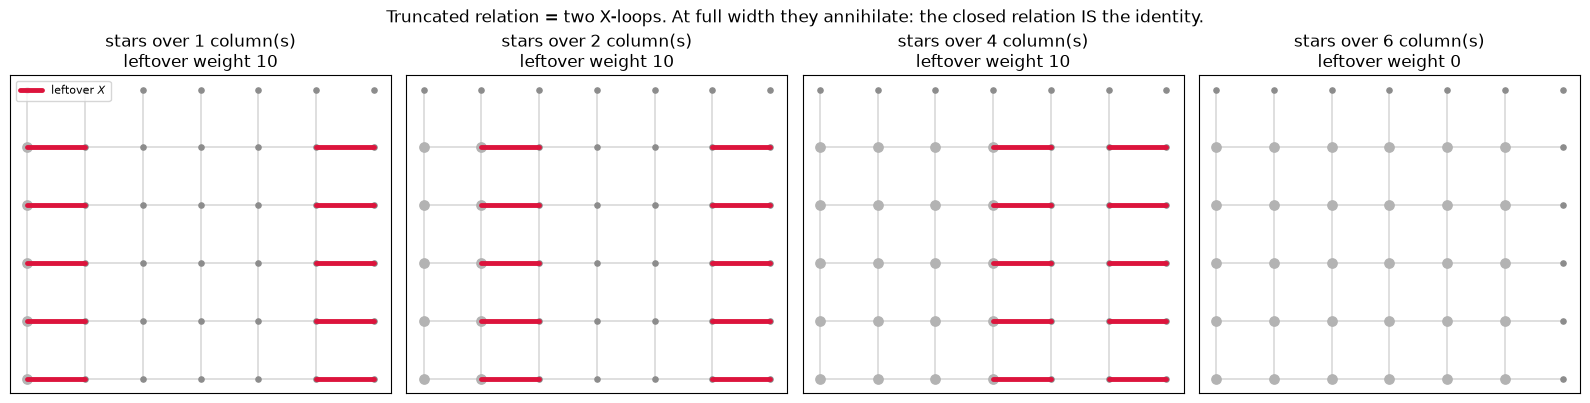

full-width truncation (the closed relation) leftover: 0 -> identity, as required


In [12]:
def strip(Lx, Ly, axis, width):
    """Truncate the uniform relation to a strip: the first `width` columns (or rows)."""
    t = torch.zeros((Ly, Lx), dtype=torch.int64)
    if axis == "columns":
        t[:, :width] = 1
    else:
        t[:width, :] = 1
    return t

Lx, Ly = 6, 5
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0))
for ax, w in zip(axes, [1, 2, 4, Lx]):
    t = strip(Lx, Ly, "columns", w)
    draw_lattice(Lx, Ly, ax)
    for i in range(Ly):
        for j in range(Lx):
            if t[i, j]:
                ax.scatter([j], [i], s=45, c="0.7", zorder=2)
    draw_support(star_support(t), ax, "crimson", label="leftover $X$")
    ax.set_title(f"stars over {w} column(s)\nleftover weight {int((star_support(t) != 0).sum())}")
    if w == 1:
        ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Truncated relation = two X-loops. At full width they annihilate: "
             "the closed relation IS the identity.", y=1.02)
plt.tight_layout(); plt.show()

print("full-width truncation (the closed relation) leftover:",
      int(star_support(strip(Lx, Ly, "columns", Lx)).abs().sum()), "-> identity, as required")

### The four logical operators, and $k=2$ a second way

Reading a single loop off the cut of each truncation gives four operators. Two independent
truncation directions $\times$ two species:

| operator | from | support |
|---|---|---|
| $\bar X_1$ | stars truncated in columns | $x$-edges at fixed column — dual loop winding $y$ |
| $\bar X_2$ | stars truncated in rows | $y$-edges at fixed row — dual loop winding $x$ |
| $\bar Z_1$ | plaquettes truncated in rows | $x$-edges at fixed row — direct loop winding $x$ |
| $\bar Z_2$ | plaquettes truncated in columns | $y$-edges at fixed column — direct loop winding $y$ |

Each must (i) commute with every stabilizer, (ii) not itself be a product of stabilizers, and
(iii) pair non-trivially with exactly one partner. The number of conjugate pairs is $k$ — an
independent route to the same $2$, computed from the truncated operators rather than from the ranks.

check (i) commutes with all stabilizers, (ii) not a stabilizer product:

  X1: weight 5   commutes with all stabilizers: True   is itself a stabilizer: False
  X2: weight 6   commutes with all stabilizers: True   is itself a stabilizer: False
  Z1: weight 6   commutes with all stabilizers: True   is itself a stabilizer: False
  Z2: weight 5   commutes with all stabilizers: True   is itself a stabilizer: False

pairing matrix <Xi, Zj> mod p:
[[1 0]
 [0 1]]

conjugate pairs = rank of pairing matrix = 2   ->  GSD = 2^2 = 4
Agrees with the rank-nullity count of section 6.


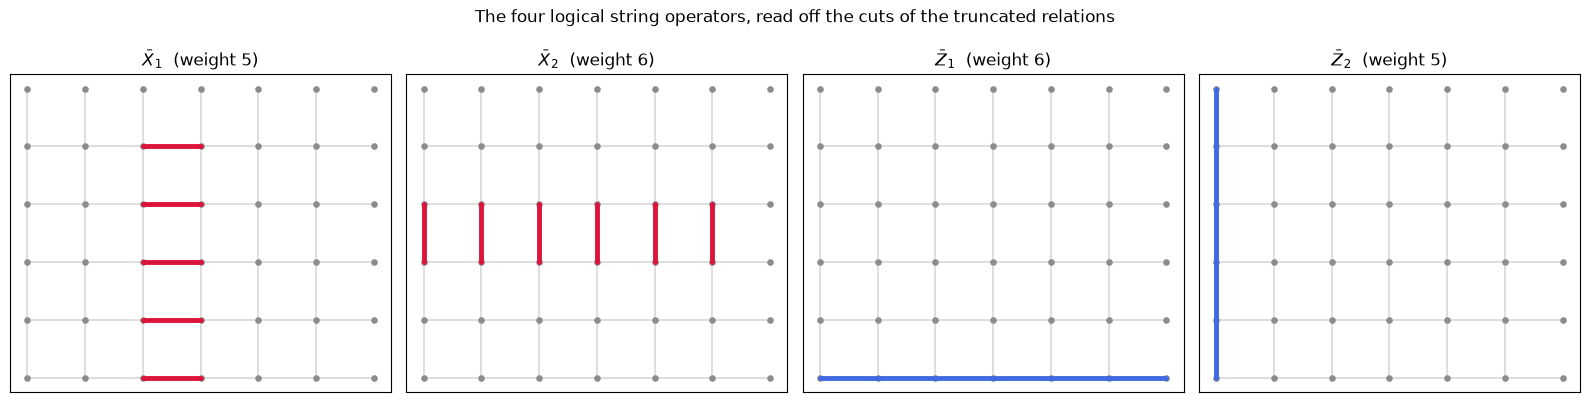

In [13]:
def cut(support, keep_axis, index):
    """Keep one boundary of a truncated relation: the loop at the cut."""
    s = torch.zeros_like(support)
    if keep_axis == "col":
        s[:, :, index] = support[:, :, index]
    else:
        s[:, index, :] = support[:, index, :]
    return s

Lx, Ly, p = 6, 5, 2
Fa, Fb = build_map(star_support, Lx, Ly, p), build_map(plaq_support, Lx, Ly, p)

X1 = cut(star_support(strip(Lx, Ly, "columns", 3), p), "col", 2)     # x-edges, column 2
X2 = cut(star_support(strip(Lx, Ly, "rows", 3), p), "row", 2)        # y-edges, row 2
Z1 = cut(plaq_support(strip(Lx, Ly, "rows", 3), p), "row", 0)        # x-edges, row 0
Z2 = cut(plaq_support(strip(Lx, Ly, "columns", 3), p), "col", 0)     # y-edges, column 0
logicals = {"X1": X1, "X2": X2, "Z1": Z1, "Z2": Z2}

def in_column_space(F, v, p=2):
    """Is the edge-support v a product of the generators in F?"""
    return gfp_rank_fast(torch.cat([F, v.flatten().reshape(-1, 1)], 1), p) == gfp_rank_fast(F, p)

print("check (i) commutes with all stabilizers, (ii) not a stabilizer product:\n")
for name, s in logicals.items():
    partner = Fb if name.startswith("X") else Fa      # X pairs with Z-checks and vice versa
    own = Fa if name.startswith("X") else Fb
    commutes = bool(((s.flatten() @ partner) % p == 0).all())
    is_stab = in_column_space(own, s, p)
    print(f"  {name}: weight {int((s != 0).sum())}   commutes with all stabilizers: {commutes}"
          f"   is itself a stabilizer: {is_stab}")
    assert commutes and not is_stab, f"{name} is not a logical operator"

print("\npairing matrix <Xi, Zj> mod p:")
M = torch.tensor([[int((logicals[f"X{i}"].flatten() @ logicals[f"Z{j}"].flatten()) % p)
                   for j in (1, 2)] for i in (1, 2)])
print(M.numpy())
k_from_logicals = gfp_rank_fast(M, p)
print(f"\nconjugate pairs = rank of pairing matrix = {k_from_logicals}"
      f"   ->  GSD = {p}^{k_from_logicals} = {p ** k_from_logicals}")
assert k_from_logicals == gsd(Lx, Ly, p)[0], "logical count disagrees with the rank count"
print("Agrees with the rank-nullity count of section 6.")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.0))
for ax, (name, s) in zip(axes, logicals.items()):
    draw_lattice(Lx, Ly, ax)
    draw_support(s, ax, "crimson" if name.startswith("X") else "royalblue")
    ax.set_title(f"$\\bar {name[0]}_{name[1]}$  (weight {int((s != 0).sum())})")
fig.suptitle("The four logical string operators, read off the cuts of the truncated relations", y=1.02)
plt.tight_layout(); plt.show()

## 9. $\mathbb{Z}_p$ qudits: same code, $\mathrm{GSD} = p^2$

Every function above already takes `p`. Raising the modulus turns the qubit toric code into the
$\mathbb{Z}_p$ one, and the kernel argument is unchanged — $t(r) = t(r+e_x) = t(r+e_y)$ still forces
$t$ constant over any field — so $\dim\ker = 1$ per species and $\mathrm{GSD} = p^2$.

Contrast with `fractal_constraints_Nc_general.ipynb`, where changing $p$ changed the *character* of
the answer completely ($p=2$ smooth and linear, $p=3$ sparse and number-theoretic). Here it only
relabels the group: the answer is $p^2$ for every prime and every torus. That robustness is what
"topological" means operationally, and it is also the check that the orientation signs of §1 are
right — without them §7's commutation test fails for every $p > 2$.

In [14]:
print("p    Lx x Ly    dim ker F_A  dim ker F_B     k    GSD    commuting    checks\n")
for p in (2, 3, 5, 7):
    for (Lx, Ly) in [(3, 3), (5, 4)]:
        Fa, Fb = build_map(star_support, Lx, Ly, p), build_map(plaq_support, Lx, Ly, p)
        ka, kb = gfp_nullspace(Fa, p).shape[0], gfp_nullspace(Fb, p).shape[0]
        k, g = gsd(Lx, Ly, p)
        comm = bool(((Fa.T @ Fb) % p == 0).all())
        ok = validate(Lx, Ly, p, verbose=False)
        print(f"{p:<5d}{Lx} x {Ly:<8d}{ka:^13d}{kb:^12d}{k:^7d}{g:^7d}{str(comm):^13s}{ok}")
        assert comm and ok and g == p ** 2, f"Z_{p} toric code failed at {Lx}x{Ly}"

print("\nGSD = p^2 for every prime and every torus tested.")

p    Lx x Ly    dim ker F_A  dim ker F_B     k    GSD    commuting    checks

2    3 x 3             1           1         2      4       True     True
2    5 x 4             1           1         2      4       True     True
3    3 x 3             1           1         2      9       True     True


3    5 x 4             1           1         2      9       True     True
5    3 x 3             1           1         2     25       True     True
5    5 x 4             1           1         2     25       True     True
7    3 x 3             1           1         2     49       True     True
7    5 x 4             1           1         2     49       True     True

GSD = p^2 for every prime and every torus tested.


## 10. The same stencil machinery in 3D

Doc §7.1 phrases the whole method as "roll a stencil", with no reference to dimension. Writing the
stencils as explicit lists of (coefficient, offset) pairs makes that literal, and 3D then costs
nothing but a longer offset tuple.

A stencil is `{edge_species: [(coeff, offset), ...]}`, meaning *a generator sitting at site $r$
contributes* `coeff` *to edge* `(species, r + offset)`. The first cell rebuilds the 2D star and
plaquette this way and asserts they reproduce the hand-written roll functions of §1 — otherwise the
3D result rests on untested code.

In [15]:
def roll_multi(t, offset):
    for d, s in enumerate(offset):
        if s:
            t = torch.roll(t, s, d)
    return t

def stencil_support(t, stencil, n_edge, p=2):
    """Apply one generator species, given as {edge_species: [(coeff, offset), ...]}."""
    out = [torch.zeros_like(t) for _ in range(n_edge)]
    for a, terms in stencil.items():
        for c, off in terms:
            out[a] = out[a] + c * roll_multi(t, off)
    return torch.stack(out) % p

def build_map_stencil(stencils, shape, n_edge, p=2):
    """Columns = impulse responses of every (species, site). shape: lattice dims, e.g. (Ly, Lx)."""
    N = int(np.prod(shape))
    F = torch.zeros((n_edge * N, len(stencils) * N), dtype=torch.int64)
    for g, st in enumerate(stencils):
        for k in range(N):
            e = torch.zeros(N, dtype=torch.int64)
            e[k] = 1
            F[:, g * N + k] = stencil_support(e.reshape(shape), st, n_edge, p).flatten()
    return F

# (row, col) = (e_y, e_x); edge species 0 = x-edge, 1 = y-edge
STAR_2D = {0: [(+1, (0, 0)), (-1, (0, -1))],
           1: [(+1, (0, 0)), (-1, (-1, 0))]}
PLAQ_2D = {0: [(+1, (0, 0)), (-1, (+1, 0))],
           1: [(+1, (0, +1)), (-1, (0, 0))]}

Lx, Ly, p = 5, 4, 3
assert bool((build_map_stencil([STAR_2D], (Ly, Lx), 2, p) == build_map(star_support, Lx, Ly, p)).all())
assert bool((build_map_stencil([PLAQ_2D], (Ly, Lx), 2, p) == build_map(plaq_support, Lx, Ly, p)).all())
print("Stencil builder reproduces the hand-written 2D roll functions exactly (checked at p=3).")

Stencil builder reproduces the hand-written 2D roll functions exactly (checked at p=3).


### 3D toric code on $T^3$

Qubits on the edges of a cubic lattice (3 per site), one star per vertex (6 edges), and now **three**
plaquette species per site — the $xy$, $yz$ and $zx$ faces — so $3N$ $Z$-type generators against $3N$
qubits and $N$ $X$-type generators. The stencils are the obvious lifts:

$$A_v:\; \text{edge } a \to (+1, 0),\, (-1, -e_a) \quad\text{for } a = x,y,z,$$
$$B_{ab}:\; \text{edge } a \to (+1, 0),\, (-1, +e_b); \quad \text{edge } b \to (+1, +e_a),\, (-1, 0).$$

Now $n = 3N \ne m = 4N$, so the $\mathrm{GSD} = p^{\dim\ker F}$ shortcut of doc §1 is **not**
available and the $(n-m)$ term of §6 does real work: the plaquette map alone has a large kernel (all
the cube relations $\prod_{f \in \partial c} B_f = \mathbb{1}$), and only the rank formula gives the
right answer. Expected: $k = 3$, $\mathrm{GSD} = 8$ — one logical qubit per non-contractible cycle of
$T^3$, matched by $X$-string / $Z$-membrane pairs.

In [16]:
# dims: (z, y, x);  edge species 0 = x-edge, 1 = y-edge, 2 = z-edge
E = {0: (0, 0, 1), 1: (0, 1, 0), 2: (1, 0, 0)}          # unit offsets
ZERO = (0, 0, 0)

def neg(o):
    return tuple(-v for v in o)

STAR_3D = {a: [(+1, ZERO), (-1, neg(E[a]))] for a in (0, 1, 2)}
PLAQ_3D = [{a: [(+1, ZERO), (-1, E[b])],
            b: [(+1, E[a]), (-1, ZERO)]} for (a, b) in [(0, 1), (1, 2), (2, 0)]]

def gsd_3d(Lx, Ly, Lz, p=2):
    shape, N = (Lz, Ly, Lx), Lx * Ly * Lz
    Fa = build_map_stencil([STAR_3D], shape, 3, p)
    Fb = build_map_stencil(PLAQ_3D, shape, 3, p)
    assert bool(((Fa.T @ Fb) % p == 0).all()), "3D stars and plaquettes do not commute"
    n = 3 * N
    ra, rb = gfp_rank_fast(Fa, p), gfp_rank_fast(Fb, p)
    k = n - ra - rb
    return k, p ** k, n, Fa.shape[1] + Fb.shape[1], ra, rb

print("Lx x Ly x Lz   p    n     m    rank F_A  rank F_B  dim ker F_B    k    GSD\n")
for (Lx, Ly, Lz, p) in [(2, 2, 2, 2), (3, 3, 3, 2), (3, 2, 4, 2), (3, 3, 3, 3)]:
    k, g, n, m, ra, rb = gsd_3d(Lx, Ly, Lz, p)
    print(f"{Lx} x {Ly} x {Lz:<9d}{p:<5d}{n:<6d}{m:<6d}{ra:^10d}{rb:^10d}"
          f"{3*Lx*Ly*Lz - rb:^14d}{k:^6d}{g}")
    assert k == 3, "3D toric code should have k = 3"

print("\nk = 3, GSD = p^3 on T^3 -- and note dim ker F_B is large and size-dependent,")
print("so GSD = p^(dim ker) would have been badly wrong here. Only the rank formula survives.")

Lx x Ly x Lz   p    n     m    rank F_A  rank F_B  dim ker F_B    k    GSD

2 x 2 x 2        2    24    32        7         14          10        3   8
3 x 3 x 3        2    81    108       26        52          29        3   8
3 x 2 x 4        2    72    96        23        46          26        3   8
3 x 3 x 3        3    81    108       26        52          29        3   27

k = 3, GSD = p^3 on T^3 -- and note dim ker F_B is large and size-dependent,
so GSD = p^(dim ker) would have been badly wrong here. Only the rank formula survives.


## 11. What this run establishes, and where to go next

- The rolled-stencil / nullspace recipe of doc §7 reproduces the toric code exactly: $k=2$,
  $\mathrm{GSD}=4$ on $T^2$ for every $L_x,L_y$ and every prime $p$ (as $p^2$), and $k=3$ on $T^3$ —
  with no closed-form recursion derived by hand at any point.
- The commuting-projector precondition (doc §2) is **checked**, not assumed:
  $F_A^{\mathsf T}F_B \equiv 0$ over $GF(p)$, which is also what pins down the orientation signs.
- The truncation subtlety of doc §3/§7.3 is implemented: closed kernel vectors are the identity, and
  cutting them open produces the four logical strings, whose pairing matrix returns the same $k=2$
  from a completely independent direction.
- The $\mathrm{GSD}=p^{\dim\ker F}$ shortcut is a $n=m$ coincidence. It holds for the 2D toric code
  and breaks in 3D, where $\dim\ker F_B$ is large and size-dependent while $k$ stays $3$. Use
  $\mathrm{GSD} = p^{(n-m)+\dim\ker F}$.
- **Contrast, which is the reason for running this at all:** the identical machinery gave $3L-2$ for
  the six-neighbour operator and a sparse $L=2^n-2^m$ spectrum for the TD/fractal operator. A flat,
  size-independent answer is the fingerprint of conventional topological order — no UV/IR mixing, so
  none of the number theory of §7.2 is needed.

**Next:**

1. **Open boundaries.** Replace `torch.roll` with a zero-padded shift and the relations vanish:
   $\mathrm{GSD}=1$ on the disk, $2$ on a strip with two rough and two smooth boundaries. The stencil
   code is unchanged; only the shift changes.
2. **Higher genus.** $\mathrm{GSD}=4^g$ needs a lattice that is not a product of cycles, so the
   circulant structure is lost — the brute-force nullspace still works, which is exactly the
   selling point of the numerical route.
3. **Perturb away from the solvable point** (doc §6): interpolate toric code $\to$ trivial
   paramagnet and watch the four-fold degeneracy split, à la Trebst *et al.*
4. **Scaling** (doc §7.3): the maps here are block-circulant, so CRT block-diagonalisation would
   replace one $O(N^3)$ elimination with many small ones — needed before 3D sizes past $L \sim 8$.